<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/JS11/praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1 - Ilustrasi Data Non-Linier

Langkah 1a - Import Library

In [3]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

Langkah 1b - Buat Kembali Fungsi Plotting

In [4]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

Langkah 1c - Buat Data Dummy Non-Linier

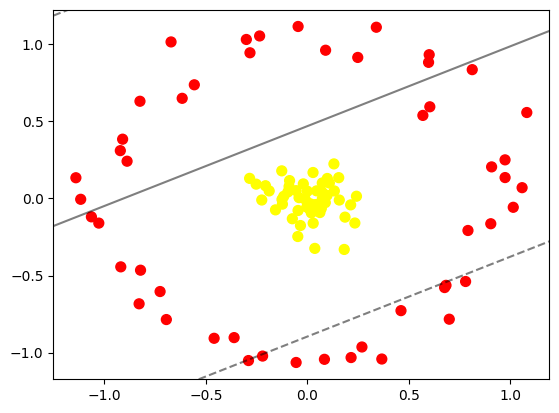

In [5]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

In [6]:
	from mpl_toolkits import mplot3d
	from ipywidgets import interact, fixed

r = np.exp(-(X ** 2).sum(1))

# Kemudian jalankan fungsi plot_3D Anda
def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180), X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 1.01473803e+00, -5.72203422e-02],
       [-4.59178053e-01, -9.06712307e-01],
       [-3.60682794e-01, -9.02266769e-01],
       [ 1.97275991e-02, -9.34148491e-02],
       [ 1.33182501e-01,  4.87646159e-02],
       [ 2.69131578e-01, -9.63125829e-01],
       [ 7.91608799e-01, -2.07635019e-01],
       [ 2.90017159e-02, -1.60258685e-01],
       [ 3.69773268e-02, -3.23708795e-01],
       [ 9.04053828e-01, -1.63898405e-01],
       [ 3.07576917e-03, -2.93964866e-02],
       [ 7.25825106e-02,  4.15029352e-02],
       [ 6.90392091e-02, -6.49835381e-02],
       [-9.21360761e-01,  3.10169164e-01],
       [-1.11661735e+00, -5.34584323e-03],
       [ 6.99531794e-01, -7.82909616e-01],
       [ 1.81925435e-01, -3.30600973e-01],
       [-2.24452983e-01, -9.96786256e-03],
       [ 3.40054539e-01,  1.11038753e+00],
       [ 6.00539196e-01,  9.32360750e-01],
       [ 1.08152337e+00,  5.57421655e-01],
       [ 7.39719627e-02, -1.14248489e-03],
       [ 1.54788684e-01,  1.34872532e-01],
       [-3.37621897e-02, -1.75431502e-01],
       [-5.48690714e-02,  5.07047625e-02],
       [-1.06383702e+00, -1.19216314e-01],
       [-6.71432274e-01,  1.01512453e+00],
       [ 6.03652263e-01,  5.94472987e-01],
       [ 9.74307335e-01,  2.50430605e-01],
       [-2.20368312e-01, -1.02201809e+00],
       [-6.94607183e-01, -7.85202424e-01],
       [-9.10046604e-01,  3.84430425e-01],
       [-4.68707770e-02, -2.46696904e-01],
       [ 6.76531520e-01, -5.77720424e-01],
       [ 8.86924263e-02, -2.69129852e-02],
       [-4.07665435e-02,  5.38343013e-03],
       [-8.88106707e-01,  2.41623498e-01],
       [-2.84289982e-01,  1.30342277e-01],
       [-2.52044471e-01,  9.28689805e-02],
       [ 5.97486507e-01,  8.82710691e-01],
       [-1.06863662e-02, -4.70857774e-03],
       [ 1.27644407e-02, -7.04240480e-02],
       [-5.56772933e-01,  7.37133328e-01],
       [-1.25949054e-01,  1.79084309e-01],
       [ 6.20175112e-02, -9.12413893e-02],
       [ 1.57558414e-01, -1.01589424e-02],
       [-2.43091008e-03, -5.58292545e-02],
       [ 7.36347932e-02,  1.00240508e-01],
       [-1.02736477e+00, -1.59709880e-01],
       [-8.28799435e-01, -6.83103012e-01],
       [ 2.13670975e-01, -4.14736728e-02],
       [-5.51440942e-02, -1.06356295e+00],
       [ 4.58864201e-02,  4.93862752e-02],
       [ 2.16528542e-04,  4.70217444e-02],
       [ 1.05835678e+00,  6.99578063e-02],
       [-4.53788328e-02,  1.11532792e+00],
       [-8.74781570e-02,  1.15826519e-01],
       [-1.56801324e-01, -7.38989178e-02],
       [-7.25436979e-01, -6.03497012e-01],
       [ 9.01052004e-02,  9.61301203e-01],
       [-7.38467786e-02, -1.31583052e-01],
       [-2.06049724e-01,  8.25989755e-02],
       [-1.16163289e-01,  1.39268301e-02],
       [ 2.81516432e-02,  1.68392473e-01],
       [ 3.67114291e-01, -1.04116176e+00],
       [ 8.12631863e-01,  8.35377419e-01],
       [-1.87873426e-01,  4.89563571e-02],
       [ 9.08122244e-01,  2.04796882e-01],
       [ 9.73671347e-02,  2.04847042e-02],
       [-1.24793229e-01, -6.38431803e-03],
       [ 2.15690186e-01, -1.03159892e+00],
       [-4.56559114e-02, -7.79562897e-02],
       [-1.22749124e-01, -3.67609180e-02],
       [ 1.85816283e-01, -1.21061082e-01],
       [ 5.69406771e-01,  5.38627179e-01],
       [ 1.77200375e-02, -3.63057718e-02],
       [ 2.34302029e-01, -1.59191451e-01],
       [-8.24576180e-01,  6.30410252e-01],
       [-6.16531586e-01,  6.49462160e-01],
       [-2.89885281e-01, -1.05107923e+00],
       [ 8.43907181e-02, -1.04309498e+00],
       [-8.21758584e-01, -4.65141328e-01],
       [-9.54875123e-02,  4.26994790e-02],
       [-1.97785149e-02,  9.45475392e-02],
       [-2.82531093e-01,  9.44759431e-01],
       [ 4.61580431e-01, -7.27433156e-01],
       [-3.00461487e-01,  1.03103272e+00],
       [ 7.79944276e-01, -5.38433247e-01],
       [ 9.85301621e-02,  1.29626127e-01],
       [ 2.42223862e-01,  1.44520289e-02],
       [-8.98322990e-02,  7.80275675e-02],
       [ 6.83345983e-01, -5.63258315e-01

Langkah 2 - Fitting Model

In [7]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

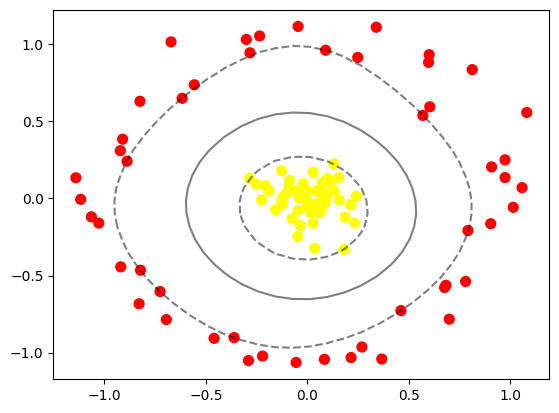

In [8]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')